# Measuring Diversity Among Trained Trading Experts

This notebook evaluates the six DAHERL experts on the EURUSD test split and compares their
behaviour with a mix of trajectory-level and action-level diversity metrics.

The analysis is organized into four stages:
1. Load the project configuration, checkpoints, and test data.
2. Recreate each expert with the architecture used during training and run deterministic inference.
3. Compare the resulting trajectories with correlation, overlap, divergence, and distance metrics.
4. Visualize the results and save a reproducible summary artifact.

## 1. Imports and Notebook Settings

The notebook keeps the evaluation deterministic and uses a consistent plotting style so the
results are easy to compare across runs.

In [4]:
from __future__ import annotations

import pickle
from pathlib import Path
from typing import Dict, List, Tuple

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import torch
import yaml
from IPython.display import display
from scipy.stats import entropy
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE
from tqdm.auto import tqdm

from diversity.metrics import action_correlation, return_correlation, trade_overlap
from environment.trading_env import TradingEnv
from experts.a2c_expert import A2CAgent
from experts.ddqn_expert import DDQNAgent
from experts.ppo_expert import PPOAgent
from experts.sac_expert import SACAgent
from experts.td3_expert import TD3Agent
from experts.tqc_expert import TQCAgent


RANDOM_SEED = 42
np.random.seed(RANDOM_SEED)
torch.manual_seed(RANDOM_SEED)

sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["figure.figsize"] = (12, 6)
plt.rcParams["axes.titleweight"] = "bold"
plt.rcParams["axes.labelsize"] = 11

c:\Users\Nabeel\miniconda3\envs\torch\lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## 2. Project Paths and Data Loading

The notebook resolves the repository root automatically so it can run from either the project
root or the `notebooks/` directory.

In [13]:
def find_project_root(start: Path | None = None) -> Path:
    start = start or Path.cwd()
    for candidate in (start, *start.parents):
        if (candidate / "configs" / "experts.yaml").exists():
            return candidate
    raise FileNotFoundError(
        "Could not locate the project root. Expected to find configs/experts.yaml "
        "in the current directory or one of its parents."
    )


def detect_asset_type(asset_name: str) -> str:
    asset_upper = asset_name.upper()
    crypto_suffixes = ("USDT", "BUSD", "USDC", "BTC", "ETH", "BNB", "XRP", "ADA", "DOGE", "SOL", "DOT")
    if any(asset_upper.endswith(suffix) for suffix in crypto_suffixes):
        return "crypto"

    forex_bases = ("EUR", "GBP", "USD", "JPY", "CHF", "CAD", "AUD", "NZD")
    if (
        len(asset_upper) == 6
        and any(asset_upper.startswith(base) for base in forex_bases)
        and any(asset_upper.endswith(base) for base in forex_bases)
    ):
        return "forex"

    return "crypto"


PROJECT_ROOT = find_project_root()
ASSET = "EURUSD"
ASSET_TYPE = detect_asset_type(ASSET)

CONFIG_PATH = PROJECT_ROOT / "configs" / "experts.yaml"
TEST_DATA_PATH = PROJECT_ROOT / "data" / "processed" / ASSET / "train.csv"
CHECKPOINT_DIR = PROJECT_ROOT / "checkpoints" / ASSET
RESULTS_DIR = PROJECT_ROOT / "storage" / ASSET / "analysis"
RESULTS_DIR.mkdir(parents=True, exist_ok=True)

with CONFIG_PATH.open("r", encoding="utf-8") as fh:
    cfg = yaml.safe_load(fh)

test_df = pd.read_csv(TEST_DATA_PATH, index_col=0, parse_dates=True)
print(f"Project root: {PROJECT_ROOT}")
print(f"Asset: {ASSET} ({ASSET_TYPE})")
print(f"Test data shape: {test_df.shape}")
print(f"Test data columns: {test_df.columns.tolist()}")
display(test_df.head(3))

Project root: c:\Users\Nabeel\Desktop\AET_itr1
Asset: EURUSD (forex)
Test data shape: (11984, 18)
Test data columns: ['open', 'high', 'low', 'close', 'volume', 'ema_20', 'ema_50', 'macd', 'macd_signal', 'rsi_14', 'vortex_14', 'atr_14', 'volatility_20', 'bb_upper', 'bb_lower', 'returns', 'return_5', 'log_volume']


,open,high,low,close,volume,ema_20,ema_50,macd,macd_signal,rsi_14,vortex_14,atr_14,volatility_20,bb_upper,bb_lower,returns,return_5,log_volume
timestamp,,,,,,,,,,,,,,,,,,
2010-02-01 10:00:00,1.39116,1.39146,1.38884,1.38977,3634,0.512415,0.526927,-0.043714,-0.281811,1.022865,-0.414687,-0.895781,-1.182307,0.435403,0.558387,-0.652263,0.444856,-0.548762
2010-02-01 11:00:00,1.38974,1.39135,1.38898,1.38970,3374,0.514084,0.527063,-0.001498,-0.225735,1.153914,-0.362696,-0.760015,-1.274033,0.435145,0.558517,-0.030338,0.325515,-0.656884
2010-02-01 12:00:00,1.38971,1.39157,1.38911,1.39096,3562,0.517518,0.527989,0.075247,-0.164636,1.343431,-0.140897,-0.676593,-1.545081,0.443545,0.556485,0.606631,0.605082,-0.577908


## 3. Agent Manifest and Feature Validation

All six experts share the same engineered feature set in this project. The table below verifies
that the expected checkpoints exist and that the configured features are available in the test data.

In [14]:
AGENT_SPECS = {
    "PPO": {"config_key": "ppo", "checkpoint": "ppo_expert.pt", "expert_id": 1, "continuous": False},
    "SAC": {"config_key": "sac", "checkpoint": "sac_expert.pt", "expert_id": 2, "continuous": True},
    "DDQN": {"config_key": "ddqn", "checkpoint": "ddqn_expert.pt", "expert_id": 3, "continuous": False},
    "TQC": {"config_key": "tqc", "checkpoint": "tqc_expert.pt", "expert_id": 4, "continuous": True},
    "TD3": {"config_key": "td3", "checkpoint": "td3_expert.pt", "expert_id": 5, "continuous": True},
    "A2C": {"config_key": "a2c", "checkpoint": "a2c_expert.pt", "expert_id": 6, "continuous": False},
}

STATE_FEATURE_COUNT = 6
DISCRETE_AGENTS = {"PPO", "DDQN", "A2C"}
CONTINUOUS_AGENTS = {"SAC", "TQC", "TD3"}
EXCLUDED_COLUMNS = {
    "open",
    "high",
    "low",
    "close",
    "volume",
    "log_volume",
    "returns",
    "return_5",
}

checkpoint_paths = {
    name: CHECKPOINT_DIR / spec["checkpoint"]
    for name, spec in AGENT_SPECS.items()
}

missing_checkpoints = [name for name, path in checkpoint_paths.items() if not path.exists()]
if missing_checkpoints:
    raise FileNotFoundError(
        "Missing checkpoints for: " + ", ".join(missing_checkpoints)
        + f". Expected all models in {CHECKPOINT_DIR}."
    )

feature_rows = []
for name, spec in AGENT_SPECS.items():
    feature_cols = list(cfg[spec["config_key"]]["features"])
    feature_rows.append(
        {
            "agent": name,
            "checkpoint": checkpoint_paths[name].name,
            "continuous": spec["continuous"],
            "feature_count": len(feature_cols),
            "features": ", ".join(feature_cols),
            "checkpoint_exists": checkpoint_paths[name].exists(),
            "features_available": all(col in test_df.columns for col in feature_cols),
        }
    )

agent_manifest = pd.DataFrame(feature_rows).set_index("agent")
display(agent_manifest)

,checkpoint,continuous,feature_count,features,checkpoint_exists,features_available
agent,,,,,,
PPO,ppo_expert.pt,False,8,"returns, log_volume, rsi_14, macd, macd_signal...",True,True
SAC,sac_expert.pt,True,8,"returns, log_volume, rsi_14, macd, macd_signal...",True,True
DDQN,ddqn_expert.pt,False,8,"returns, log_volume, rsi_14, macd, macd_signal...",True,True
TQC,tqc_expert.pt,True,8,"returns, log_volume, rsi_14, macd, macd_signal...",True,True
TD3,td3_expert.pt,True,8,"returns, log_volume, rsi_14, macd, macd_signal...",True,True
A2C,a2c_expert.pt,False,8,"returns, log_volume, rsi_14, macd, macd_signal...",True,True


## 4. Helper Functions

The helpers below make the notebook easier to read:
- `resolve_feature_columns` prefers the configured feature list and falls back to checkpoint inspection if needed.
- `make_env` rebuilds the trading environment with the same asset-specific parameters used during training.
- `load_agent` restores each checkpoint into the matching agent class.
- `deterministic_action` enforces greedy / mean-policy inference for every agent type.
- `run_agent` collects the full trajectory for later comparison.

In [15]:
def resolve_feature_columns(agent_name: str) -> List[str]:
    spec = AGENT_SPECS[agent_name]
    configured = list(cfg[spec["config_key"]]["features"])
    if configured and all(col in test_df.columns for col in configured):
        return configured

    # Fallback path for older checkpoints or config drift.
    checkpoint = torch.load(checkpoint_paths[agent_name], map_location="cpu")
    if agent_name in {"PPO", "A2C"}:
        state_dict = checkpoint.get("network") or checkpoint.get("net") or checkpoint
    elif agent_name in {"SAC", "TD3", "TQC"}:
        state_dict = checkpoint["actor"]
    elif agent_name == "DDQN":
        state_dict = checkpoint["q_network"]
    else:
        raise ValueError(f"Unsupported agent: {agent_name}")

    first_linear = next(
        tensor for tensor in state_dict.values()
        if hasattr(tensor, "ndim") and tensor.ndim == 2
    )
    expected_feature_count = int(first_linear.shape[1] - STATE_FEATURE_COUNT)
    candidates = [col for col in test_df.columns if col not in EXCLUDED_COLUMNS]
    if len(candidates) < expected_feature_count:
        raise ValueError(
            f"Could not infer {expected_feature_count} features for {agent_name}. "
            f"Only found {len(candidates)} candidate columns."
        )
    return candidates[:expected_feature_count]


def make_env(agent_name: str, feature_cols: List[str]) -> TradingEnv:
    asset_type = ASSET_TYPE
    is_continuous = AGENT_SPECS[agent_name]["continuous"]

    env_params = {
        "df": test_df,
        "feature_cols": feature_cols,
        "expert_id": AGENT_SPECS[agent_name]["expert_id"],
        "asset_type": asset_type,
        "contract_size": 1.0 if asset_type == "crypto" else 100000.0,
        "commission_rate": 0.0005 if asset_type == "crypto" else 1.5 / 100000.0,
        "spread_rate": 0.0002 if asset_type == "crypto" else 0.00005,
        "slippage_rate": 0.0001 if asset_type == "crypto" else 0.00001,
        "leverage": 5 if asset_type == "crypto" else 30,
        "maintenance_margin_ratio": 0.5,
        "initial_balance": 10000.0,
        "window_size": 20,
        "reward_scale": 1.0,
        "clip_reward": (-10.0, 10.0),
        "max_position_fraction": 0.95,
        "continuous_actions": is_continuous,
        "normalize_obs": True,
    }
    return TradingEnv(**env_params)


def compute_sharpe(returns: List[float], eps: float = 1e-8) -> float:
    if len(returns) < 2:
        return 0.0
    arr = np.asarray(returns, dtype=np.float64)
    std = arr.std(ddof=1)
    if std < eps or np.isnan(std):
        return 0.0
    return float(arr.mean() / (std + eps))


def compute_sortino(returns: List[float], eps: float = 1e-8) -> float:
    if len(returns) < 2:
        return 0.0
    arr = np.asarray(returns, dtype=np.float64)
    downside = arr[arr < 0]
    if len(downside) < 2:
        return 0.0
    down_std = downside.std(ddof=1)
    if down_std < eps or np.isnan(down_std):
        return 0.0
    return float(arr.mean() / (down_std + eps))


def compute_max_drawdown(equity_curve: List[float]) -> float:
    if len(equity_curve) < 2:
        return 0.0
    arr = np.asarray([max(e, 1e-4) for e in equity_curve], dtype=np.float64)
    peak = np.maximum.accumulate(arr)
    dd = (peak - arr) / (peak + 1e-8)
    return float(np.max(dd))


def action_to_signal(action, agent_name: str) -> float:
    if agent_name in CONTINUOUS_AGENTS:
        return float(np.clip(np.asarray(action, dtype=np.float32).reshape(-1)[0], -1.0, 1.0))
    mapping = {0: -1.0, 1: 0.0, 2: 1.0}
    return mapping.get(int(action), 0.0)


def deterministic_action(agent_name: str, agent, obs: np.ndarray):
    state = torch.as_tensor(obs, dtype=torch.float32, device=agent.device).unsqueeze(0)

    if agent_name == "PPO":
        with torch.no_grad():
            logits, _ = agent.network(state)
            action = torch.argmax(logits, dim=-1).item()
        return int(action)

    if agent_name == "DDQN":
        with torch.no_grad():
            q_values = agent.q_network(state)
            action = torch.argmax(q_values, dim=-1).item()
        return int(action)

    if agent_name == "A2C":
        with torch.no_grad():
            logits, _ = agent.net(state)
            action = torch.argmax(logits, dim=-1).item()
        return int(action)

    if agent_name == "TD3":
        with torch.no_grad():
            action = agent.actor(state).cpu().numpy().reshape(-1).astype(np.float32)
        return action

    if agent_name in {"SAC", "TQC"}:
        with torch.no_grad():
            mu, _ = agent.actor(state)
            action = torch.tanh(mu).cpu().numpy().reshape(-1).astype(np.float32)
        return action

    raise ValueError(f"Unsupported agent for deterministic inference: {agent_name}")


def run_agent(agent_name: str, agent, env: TradingEnv) -> dict:
    obs, info = env.reset(seed=RANDOM_SEED)
    terminated = False
    truncated = False

    raw_actions: List[float] = []
    action_signals: List[float] = []
    positions: List[float] = []
    returns: List[float] = []
    equities: List[float] = [float(env.initial_balance)]

    with torch.no_grad():
        while not (terminated or truncated):
            action = deterministic_action(agent_name, agent, obs)
            env_action = action if agent_name in DISCRETE_AGENTS else action.reshape(-1)
            next_obs, reward, terminated, truncated, info = env.step(env_action)

            raw_actions.append(float(np.asarray(action).reshape(-1)[0]))
            action_signals.append(action_to_signal(action, agent_name))
            positions.append(float(info.get("position_frac", 0.0)))
            returns.append(float(info.get("step_return", 0.0)))
            equities.append(float(info.get("equity", env.initial_balance)))

            obs = next_obs

    final_equity = float(equities[-1])
    initial_equity = float(equities[0])
    total_return = (final_equity - initial_equity) / (initial_equity + 1e-8)

    return {
        "raw_actions": np.asarray(raw_actions, dtype=np.float32),
        "action_signals": np.asarray(action_signals, dtype=np.float32),
        "positions": np.asarray(positions, dtype=np.float32),
        "returns": np.asarray(returns, dtype=np.float32),
        "equity": np.asarray(equities, dtype=np.float32),
        "final_equity": final_equity,
        "total_return": float(total_return),
        "length": len(raw_actions),
    }


def align_trajectories(trajectories: Dict[str, dict]) -> int:
    if not trajectories:
        raise RuntimeError("No trajectories were generated.")
    min_len = min(traj["length"] for traj in trajectories.values())
    for traj in trajectories.values():
        traj["raw_actions"] = traj["raw_actions"][:min_len]
        traj["action_signals"] = traj["action_signals"][:min_len]
        traj["positions"] = traj["positions"][:min_len]
        traj["returns"] = traj["returns"][:min_len]
        traj["equity"] = traj["equity"][: min_len + 1]
    return min_len

## 5. Agent Builders

The constructors below mirror the training configuration closely so each checkpoint is evaluated
with the same network shape and action space it was trained with.

In [16]:
def build_agent(agent_name: str, state_dim: int):
    spec = AGENT_SPECS[agent_name]
    agent_cfg = cfg[spec["config_key"]]
    device = "cpu"

    if agent_name == "PPO":
        return PPOAgent(
            state_dim=state_dim,
            action_dim=3,
            lr=agent_cfg["learning_rate"],
            gamma=agent_cfg["gamma"],
            gae_lambda=agent_cfg["gae_lambda"],
            clip_eps=agent_cfg["clip_eps"],
            entropy_coef=agent_cfg["entropy_coef"],
            entropy_coef_final=agent_cfg.get("entropy_coef_final", 0.001),
            value_coef=agent_cfg["value_coef"],
            max_grad_norm=agent_cfg["max_grad_norm"],
            update_epochs=agent_cfg["update_epochs"],
            batch_size=agent_cfg["batch_size"],
            rollout_steps=agent_cfg["rollout_steps"],
            hidden_dim=agent_cfg["hidden_dim"],
            num_layers=agent_cfg["num_layers"],
            activation=agent_cfg["activation"],
            lr_anneal_steps=agent_cfg.get("lr_anneal_steps", 0),
            entropy_anneal_steps=agent_cfg.get("entropy_anneal_steps", 0),
            clip_value_loss=agent_cfg.get("clip_value_loss", True),
            target_kl=agent_cfg.get("target_kl", 0.02),
            device=device,
        )

    if agent_name == "SAC":
        return SACAgent(
            state_dim=state_dim,
            action_dim=1,
            lr=agent_cfg["learning_rate"],
            gamma=agent_cfg["gamma"],
            tau=agent_cfg["tau"],
            alpha=agent_cfg["alpha"],
            buffer_size=agent_cfg["buffer_size"],
            batch_size=agent_cfg["batch_size"],
            warmup_steps=agent_cfg["warmup_steps"],
            max_grad_norm=agent_cfg["max_grad_norm"],
            hidden_dim=agent_cfg["hidden_dim"],
            num_layers=agent_cfg["num_layers"],
            activation=agent_cfg["activation"],
            log_std_min=agent_cfg["log_std_min"],
            log_std_max=agent_cfg["log_std_max"],
            device=device,
        )

    if agent_name == "DDQN":
        return DDQNAgent(
            state_dim=state_dim,
            action_dim=3,
            lr=agent_cfg["learning_rate"],
            gamma=agent_cfg["gamma"],
            batch_size=agent_cfg["batch_size"],
            buffer_size=agent_cfg["buffer_size"],
            target_update_freq=agent_cfg["target_update_freq"],
            epsilon_start=agent_cfg["epsilon_start"],
            epsilon_end=agent_cfg["epsilon_end"],
            epsilon_decay=agent_cfg["epsilon_decay"],
            dueling=agent_cfg["dueling"],
            warmup_steps=agent_cfg["warmup_steps"],
            max_grad_norm=agent_cfg["max_grad_norm"],
            hidden_dim=agent_cfg["hidden_dim"],
            num_layers=agent_cfg["num_layers"],
            activation=agent_cfg["activation"],
            device=device,
        )

    if agent_name == "TQC":
        return TQCAgent(
            state_dim=state_dim,
            action_dim=1,
            lr=agent_cfg["learning_rate"],
            lr_actor=agent_cfg["lr_actor"],
            lr_critic=agent_cfg["lr_critic"],
            gamma=agent_cfg["gamma"],
            tau=agent_cfg["tau"],
            buffer_size=agent_cfg["buffer_size"],
            batch_size=agent_cfg["batch_size"],
            warmup_steps=agent_cfg["warmup_steps"],
            hidden_dim=agent_cfg["hidden_dim"],
            actor_hidden_dim=agent_cfg.get("actor_hidden_dim"),
            critic_hidden_dim=agent_cfg.get("critic_hidden_dim"),
            actor_num_layers=agent_cfg.get("actor_num_layers", 2),
            critic_num_layers=agent_cfg.get("critic_num_layers", 2),
            activation=agent_cfg["activation"],
            log_std_min=agent_cfg["log_std_min"],
            log_std_max=agent_cfg["log_std_max"],
            n_critics=agent_cfg["n_critics"],
            n_quantiles=agent_cfg["n_quantiles"],
            top_quantiles_to_drop=agent_cfg["top_quantiles_to_drop"],
            auto_entropy_tuning=agent_cfg["auto_entropy_tuning"],
            alpha=agent_cfg["alpha"],
            grad_norm_clip=agent_cfg["grad_norm_clip"],
            device=device,
        )

    if agent_name == "TD3":
        return TD3Agent(
            state_dim=state_dim,
            action_dim=1,
            lr_actor=agent_cfg["lr_actor"],
            lr_critic=agent_cfg["lr_critic"],
            gamma=agent_cfg["gamma"],
            tau=agent_cfg["tau"],
            buffer_size=agent_cfg["buffer_size"],
            batch_size=agent_cfg["batch_size"],
            warmup_steps=agent_cfg["warmup_steps"],
            exploration_noise=agent_cfg["exploration_noise"],
            policy_noise=agent_cfg["policy_noise"],
            noise_clip=agent_cfg["noise_clip"],
            policy_delay=agent_cfg["policy_delay"],
            hidden_dim=agent_cfg["hidden_dim"],
            actor_hidden_dim=agent_cfg.get("actor_hidden_dim"),
            critic_hidden_dim=agent_cfg.get("critic_hidden_dim"),
            actor_num_layers=agent_cfg.get("actor_num_layers", 2),
            critic_num_layers=agent_cfg.get("critic_num_layers", 2),
            activation=agent_cfg["activation"],
            grad_norm_clip=agent_cfg["grad_norm_clip"],
            device=device,
        )

    if agent_name == "A2C":
        return A2CAgent(
            state_dim=state_dim,
            num_actions=3,
            lr=agent_cfg["lr"],
            gamma=agent_cfg["gamma"],
            gae_lambda=agent_cfg["gae_lambda"],
            entropy_coef=agent_cfg["entropy_coef"],
            entropy_coef_final=agent_cfg.get("entropy_coef_final", 0.001),
            entropy_anneal_steps=agent_cfg.get("entropy_anneal_steps", 0),
            value_coef=agent_cfg["value_coef"],
            max_grad_norm=agent_cfg["max_grad_norm"],
            hidden_dim=agent_cfg["hidden_dim"],
            num_layers=agent_cfg["num_layers"],
            activation=agent_cfg["activation"],
            n_steps=agent_cfg["n_steps"],
            normalize_rewards=agent_cfg["normalize_rewards"],
            normalize_advantages=agent_cfg["normalize_advantages"],
            lr_anneal_steps=agent_cfg.get("lr_anneal_steps", 0),
            device=device,
        )

    raise ValueError(f"Unsupported agent: {agent_name}")


def load_agent(agent_name: str, state_dim: int, checkpoint_path: Path):
    agent = build_agent(agent_name, state_dim)
    checkpoint = torch.load(checkpoint_path, map_location="cpu")

    if agent_name == "PPO":
        state_dict = checkpoint.get("network") or checkpoint.get("net") or checkpoint
        agent.network.load_state_dict(state_dict)

    elif agent_name == "SAC":
        agent.actor.load_state_dict(checkpoint["actor"])
        agent.critic.load_state_dict(checkpoint["critic"])
        agent.critic_target.load_state_dict(checkpoint["critic_target"])
        if "log_alpha" in checkpoint:
            agent.log_alpha.data = torch.as_tensor(checkpoint["log_alpha"], device=agent.device)

    elif agent_name == "DDQN":
        agent.q_network.load_state_dict(checkpoint["q_network"])
        agent.target_network.load_state_dict(checkpoint["target_network"])

    elif agent_name == "TQC":
        agent.actor.load_state_dict(checkpoint["actor"])
        for critic, critic_state in zip(agent.critics, checkpoint["critics"]):
            critic.load_state_dict(critic_state)
        for critic_t, critic_state in zip(agent.critics_target, checkpoint["critics_target"]):
            critic_t.load_state_dict(critic_state)
        if "log_alpha" in checkpoint:
            agent.log_alpha.data = torch.as_tensor(checkpoint["log_alpha"], device=agent.device)

    elif agent_name == "TD3":
        agent.actor.load_state_dict(checkpoint["actor"])
        agent.critic.load_state_dict(checkpoint["critic"])
        agent.actor_target.load_state_dict(checkpoint["actor_target"])
        agent.critic_target.load_state_dict(checkpoint["critic_target"])

    elif agent_name == "A2C":
        state_dict = checkpoint.get("net") or checkpoint
        agent.net.load_state_dict(state_dict)

    else:
        raise ValueError(f"Unsupported agent: {agent_name}")

    return agent

## 6. Deterministic Evaluation

Each agent is run once on the EURUSD test split. Discrete agents use greedy actions, while
continuous agents use deterministic policy outputs rather than sampled actions.

In [17]:
agent_order = ["PPO", "SAC", "DDQN", "TQC", "TD3", "A2C"]
trajectories: Dict[str, dict] = {}

for agent_name in tqdm(agent_order, desc="Evaluating experts"):
    feature_cols = resolve_feature_columns(agent_name)
    env = make_env(agent_name, feature_cols)
    state_dim = env.observation_space.shape[0]
    agent = load_agent(agent_name, state_dim, checkpoint_paths[agent_name])
    trajectory = run_agent(agent_name, agent, env)
    trajectory["feature_cols"] = feature_cols
    trajectory["checkpoint"] = str(checkpoint_paths[agent_name])
    trajectories[agent_name] = trajectory

    print(
        f"{agent_name}: length={trajectory['length']}, "
        f"final_equity={trajectory['final_equity']:.2f}, "
        f"total_return={trajectory['total_return'] * 100:.2f}%"
    )

min_len = align_trajectories(trajectories)
print(f"All trajectories aligned to the shortest run: {min_len} steps")

performance_rows = []
for agent_name, traj in trajectories.items():
    equity_curve = traj["equity"]
    performance_rows.append(
        {
            "agent": agent_name,
            "length": traj["length"],
            "final_equity": traj["final_equity"],
            "total_return": traj["total_return"],
            "sharpe": compute_sharpe(traj["returns"].tolist()),
            "sortino": compute_sortino(traj["returns"].tolist()),
            "max_drawdown": compute_max_drawdown(equity_curve.tolist()),
            "mean_abs_position": float(np.mean(np.abs(traj["positions"]))),
            "mean_abs_action_signal": float(np.mean(np.abs(traj["action_signals"]))),
        }
    )

performance_df = pd.DataFrame(performance_rows).set_index("agent")
display(performance_df.style.format(
    {
        "final_equity": "{:.2f}",
        "total_return": "{:.2%}",
        "sharpe": "{:.3f}",
        "sortino": "{:.3f}",
        "max_drawdown": "{:.2%}",
        "mean_abs_position": "{:.3f}",
        "mean_abs_action_signal": "{:.3f}",
    }
))

Evaluating experts:  17%|█▋        | 1/6 [00:27<02:18, 27.79s/it]

PPO: length=11964, final_equity=9681.40, total_return=-3.19%


Evaluating experts:  33%|███▎      | 2/6 [00:56<01:53, 28.43s/it]

SAC: length=11964, final_equity=10799.50, total_return=7.99%


Evaluating experts:  50%|█████     | 3/6 [01:28<01:29, 29.84s/it]

DDQN: length=11964, final_equity=12038.05, total_return=20.38%


... (3 outputs left out)

TD3: length=11964, final_equity=11213.45, total_return=12.13%


Evaluating experts: 100%|██████████| 6/6 [02:45<00:00, 27.61s/it]

A2C: length=11964, final_equity=9831.21, total_return=-1.69%
All trajectories aligned to the shortest run: 11964 steps


,length,final_equity,total_return,sharpe,sortino,max_drawdown,mean_abs_position,mean_abs_action_signal
agent,,,,,,,,
PPO,11964,9681.40,-3.19%,-0.001,-0.002,13.25%,0.944,0.993
SAC,11964,10799.50,7.99%,0.006,0.008,19.79%,0.811,0.853
DDQN,11964,12038.05,20.38%,0.015,0.017,9.22%,0.578,0.609
TQC,11964,11345.12,13.45%,0.009,0.013,15.38%,0.762,0.802
TD3,11964,11213.45,12.13%,0.008,0.011,9.92%,0.829,0.873
A2C,11964,9831.21,-1.69%,-0.000,-0.000,13.80%,0.950,1.000


## 7. Pairwise Diversity Metrics

The matrices below compare action signals, positions, returns, and distributional shape after
all trajectories have been truncated to the same length.

In [18]:
def three_bin_distribution(seq: np.ndarray) -> np.ndarray:
    clipped = np.clip(np.asarray(seq, dtype=np.float64), -1.0, 1.0)
    bins = [-1.0, -1.0 / 3.0, 1.0 / 3.0, 1.0]
    counts, _ = np.histogram(clipped, bins=bins)
    total = counts.sum()
    if total == 0:
        return np.array([1.0, 0.0, 0.0], dtype=np.float64)
    return counts / total


def standardized_sequence(seq: np.ndarray) -> np.ndarray:
    seq = np.asarray(seq, dtype=np.float64)
    return (seq - seq.mean()) / (seq.std() + 1e-8)


def compute_pairwise_metrics(trajectories: Dict[str, dict]) -> Dict[str, pd.DataFrame]:
    names = list(trajectories.keys())
    n_agents = len(names)

    signed_action_corr = np.eye(n_agents, dtype=np.float64)
    abs_action_similarity = np.eye(n_agents, dtype=np.float64)
    return_similarity = np.eye(n_agents, dtype=np.float64)
    position_corr = np.eye(n_agents, dtype=np.float64)
    trade_overlap_matrix = np.eye(n_agents, dtype=np.float64)
    jsd_matrix = np.zeros((n_agents, n_agents), dtype=np.float64)
    euclidean_matrix = np.zeros((n_agents, n_agents), dtype=np.float64)
    absdiff_matrix = np.zeros((n_agents, n_agents), dtype=np.float64)

    for i, name_i in enumerate(names):
        for j, name_j in enumerate(names):
            if i == j:
                continue

            a_i = trajectories[name_i]["action_signals"]
            a_j = trajectories[name_j]["action_signals"]
            p_i = trajectories[name_i]["positions"]
            p_j = trajectories[name_j]["positions"]
            r_i = trajectories[name_i]["returns"]
            r_j = trajectories[name_j]["returns"]

            if np.std(a_i) > 1e-8 and np.std(a_j) > 1e-8:
                signed_action_corr[i, j] = float(np.corrcoef(a_i, a_j)[0, 1])
            else:
                signed_action_corr[i, j] = 0.0

            if np.std(p_i) > 1e-8 and np.std(p_j) > 1e-8:
                position_corr[i, j] = float(np.corrcoef(p_i, p_j)[0, 1])
            else:
                position_corr[i, j] = 0.0

            abs_action_similarity[i, j] = action_correlation(a_i, a_j)
            return_similarity[i, j] = return_correlation(r_i, r_j)
            trade_overlap_matrix[i, j] = trade_overlap(a_i, a_j, threshold=0.05)

            dist_i = three_bin_distribution(a_i)
            dist_j = three_bin_distribution(a_j)
            mixture = 0.5 * (dist_i + dist_j)
            jsd = 0.5 * (entropy(dist_i, mixture, base=2) + entropy(dist_j, mixture, base=2))
            jsd_matrix[i, j] = float(jsd)

            a_i_norm = standardized_sequence(a_i)
            a_j_norm = standardized_sequence(a_j)
            euclidean_matrix[i, j] = float(np.linalg.norm(a_i_norm - a_j_norm) / np.sqrt(len(a_i_norm)))
            absdiff_matrix[i, j] = float(np.mean(np.abs(a_i - a_j)))

    return {
        "signed_action_corr": pd.DataFrame(signed_action_corr, index=names, columns=names),
        "abs_action_similarity": pd.DataFrame(abs_action_similarity, index=names, columns=names),
        "return_similarity": pd.DataFrame(return_similarity, index=names, columns=names),
        "position_corr": pd.DataFrame(position_corr, index=names, columns=names),
        "trade_overlap": pd.DataFrame(trade_overlap_matrix, index=names, columns=names),
        "jsd_bits": pd.DataFrame(jsd_matrix, index=names, columns=names),
        "euclidean": pd.DataFrame(euclidean_matrix, index=names, columns=names),
        "mean_abs_action_diff": pd.DataFrame(absdiff_matrix, index=names, columns=names),
    }


pairwise = compute_pairwise_metrics(trajectories)

display(pairwise["signed_action_corr"].round(3))
display(pairwise["position_corr"].round(3))
display(pairwise["return_similarity"].round(3))
display(pairwise["trade_overlap"].round(3))
display(pairwise["jsd_bits"].round(3))
display(pairwise["euclidean"].round(3))

,PPO,SAC,DDQN,TQC,TD3,A2C
PPO,1.000,0.165,0.137,0.267,0.393,-0.415
SAC,0.165,1.000,0.086,0.170,0.309,-0.164
DDQN,0.137,0.086,1.000,0.171,0.274,0.065
TQC,0.267,0.170,0.171,1.000,0.377,-0.150
TD3,0.393,0.309,0.274,0.377,1.000,-0.302
A2C,-0.415,-0.164,0.065,-0.150,-0.302,1.000


,PPO,SAC,DDQN,TQC,TD3,A2C
PPO,1.000,0.165,0.138,0.267,0.393,-0.415
SAC,0.165,1.000,0.086,0.170,0.309,-0.164
DDQN,0.138,0.086,1.000,0.171,0.274,0.065
TQC,0.267,0.170,0.171,1.000,0.377,-0.150
TD3,0.393,0.309,0.274,0.377,1.000,-0.302
A2C,-0.415,-0.164,0.065,-0.150,-0.302,1.000


,PPO,SAC,DDQN,TQC,TD3,A2C
PPO,1.000,0.138,0.100,0.316,0.377,0.406
SAC,0.138,1.000,0.160,0.453,0.279,0.567
DDQN,0.100,0.160,1.000,0.129,0.255,0.009
TQC,0.316,0.453,0.129,1.000,0.387,0.532
TD3,0.377,0.279,0.255,0.387,1.000,0.348
A2C,0.406,0.567,0.009,0.532,0.348,1.000


,PPO,SAC,DDQN,TQC,TD3,A2C
PPO,1.000,0.584,0.362,0.627,0.683,0.309
SAC,0.584,1.000,0.352,0.715,0.653,0.208
DDQN,0.362,0.352,1.000,0.370,0.409,0.287
TQC,0.627,0.715,0.370,1.000,0.699,0.251
TD3,0.683,0.653,0.409,0.699,1.000,0.312
A2C,0.309,0.208,0.287,0.251,0.312,1.000


,PPO,SAC,DDQN,TQC,TD3,A2C
PPO,0.000,0.104,0.208,0.077,0.024,0.170
SAC,0.104,0.000,0.167,0.006,0.050,0.468
DDQN,0.208,0.167,0.000,0.125,0.119,0.361
TQC,0.077,0.006,0.125,0.000,0.025,0.396
TD3,0.024,0.050,0.119,0.025,0.000,0.240
A2C,0.170,0.468,0.361,0.396,0.240,0.000


,PPO,SAC,DDQN,TQC,TD3,A2C
PPO,0.000,1.292,1.313,1.211,1.102,1.682
SAC,1.292,0.000,1.352,1.288,1.175,1.526
DDQN,1.313,1.352,0.000,1.288,1.205,1.368
TQC,1.211,1.288,1.288,0.000,1.116,1.517
TD3,1.102,1.175,1.205,1.116,0.000,1.614
A2C,1.682,1.526,1.368,1.517,1.614,0.000


## 8. Visualizations

Heatmaps summarize the pairwise metrics, the distribution plots show how each agent uses the action
space, and the PCA / t-SNE views provide a compact comparison of the full action trajectories.

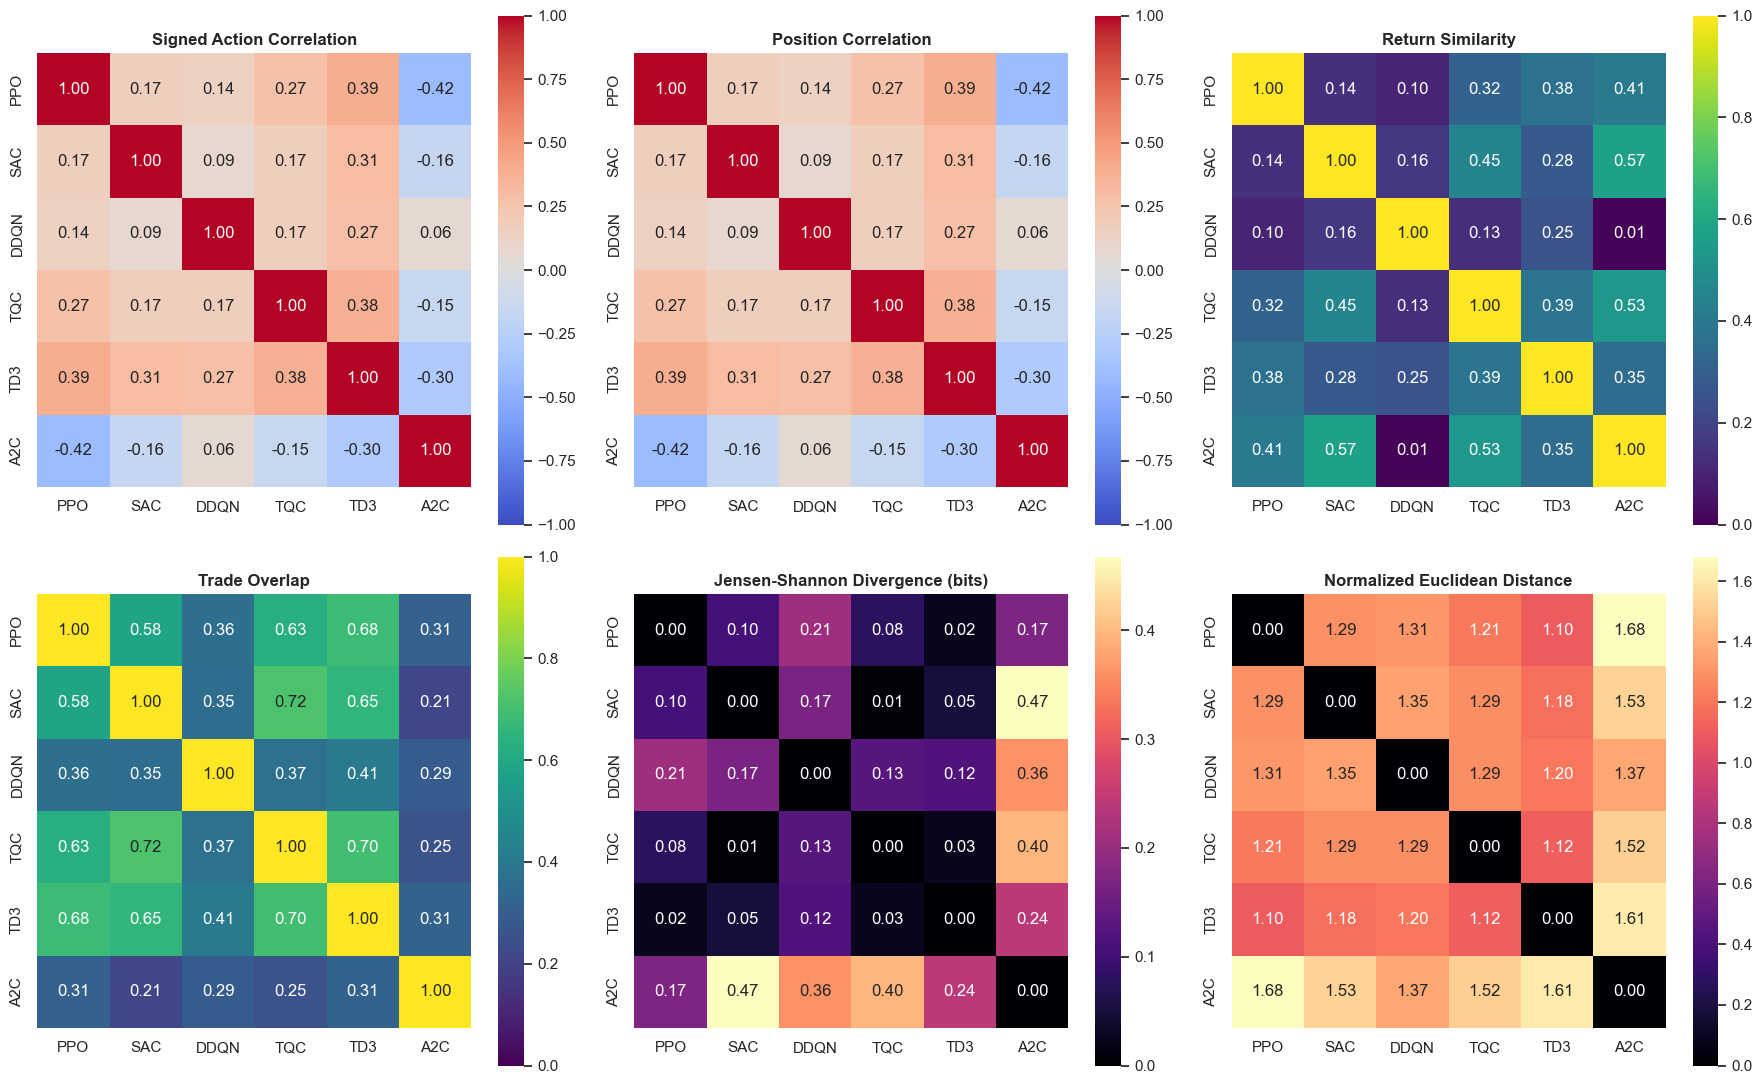

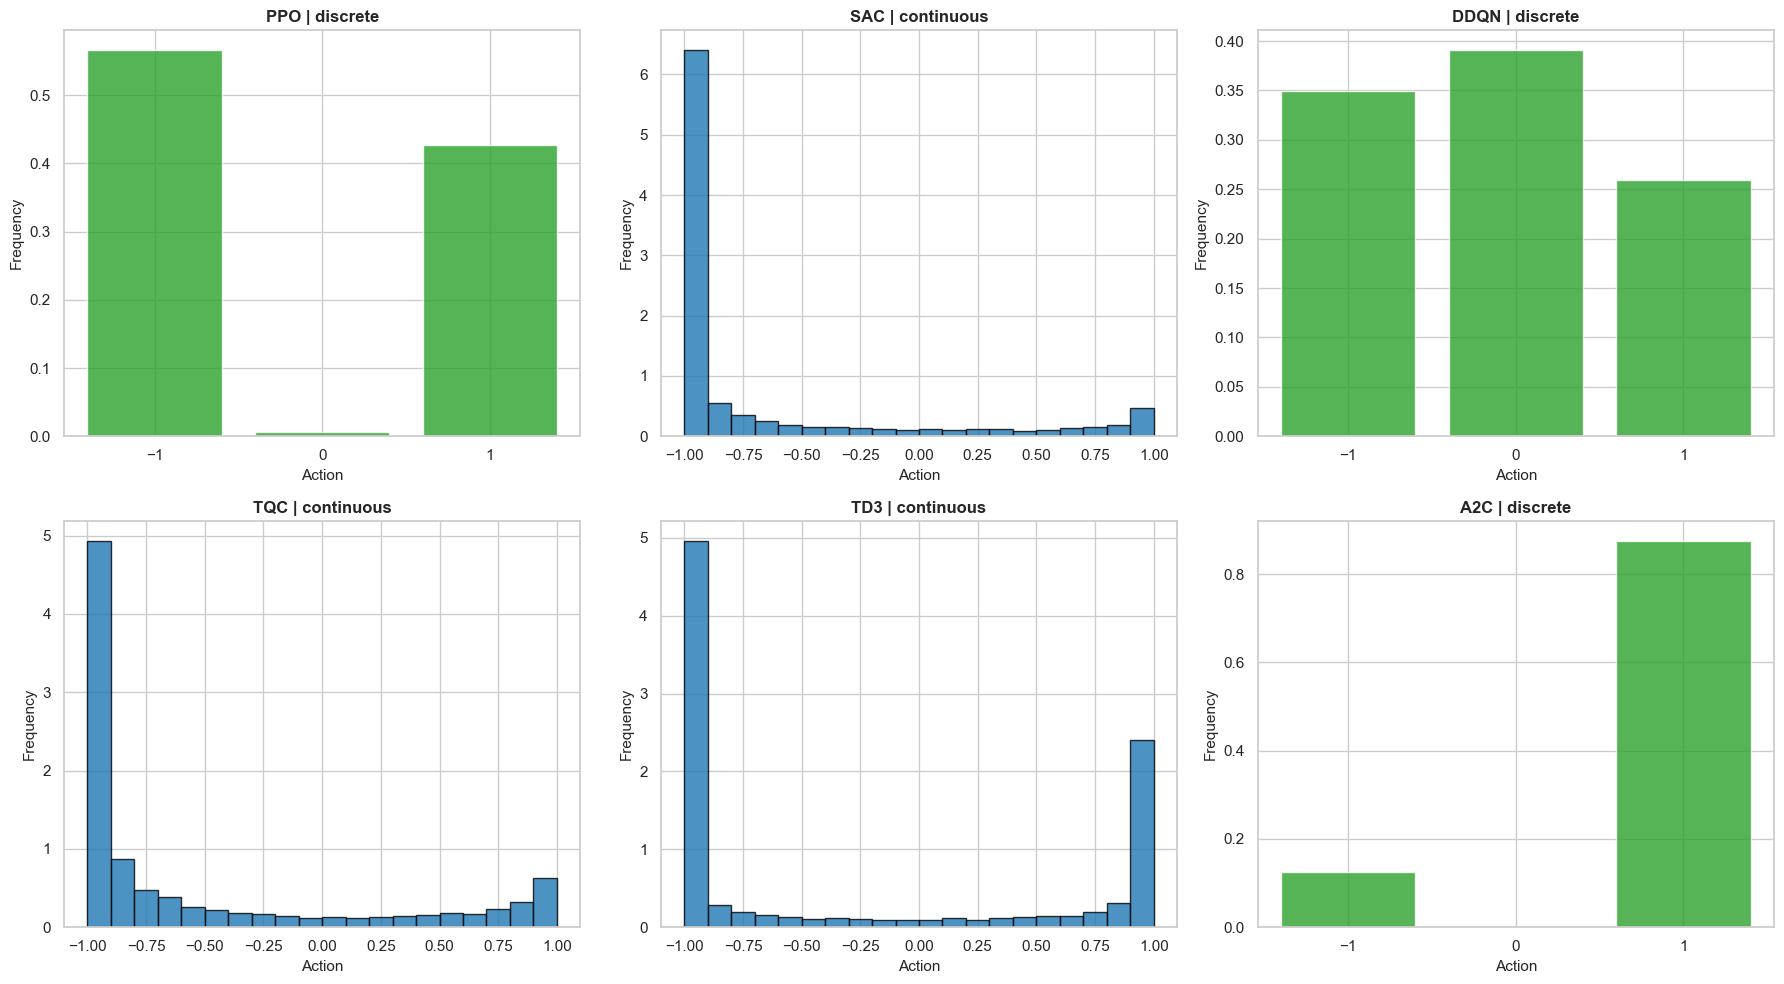

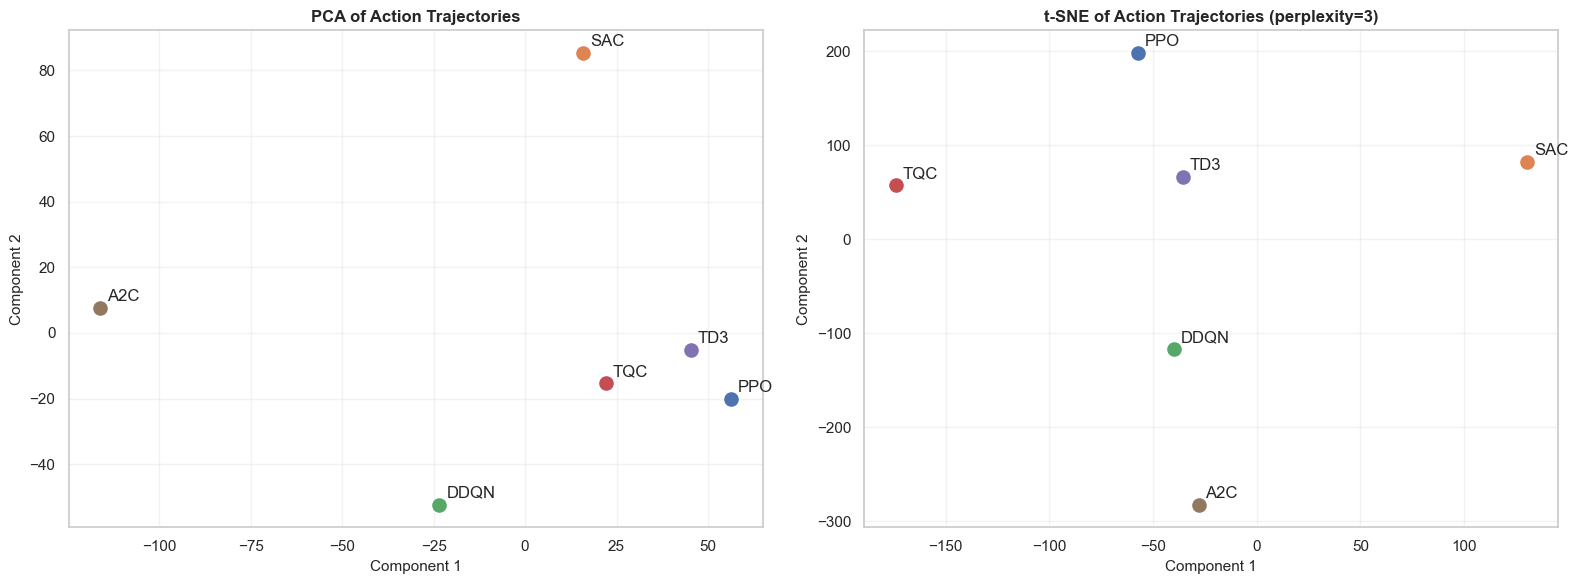

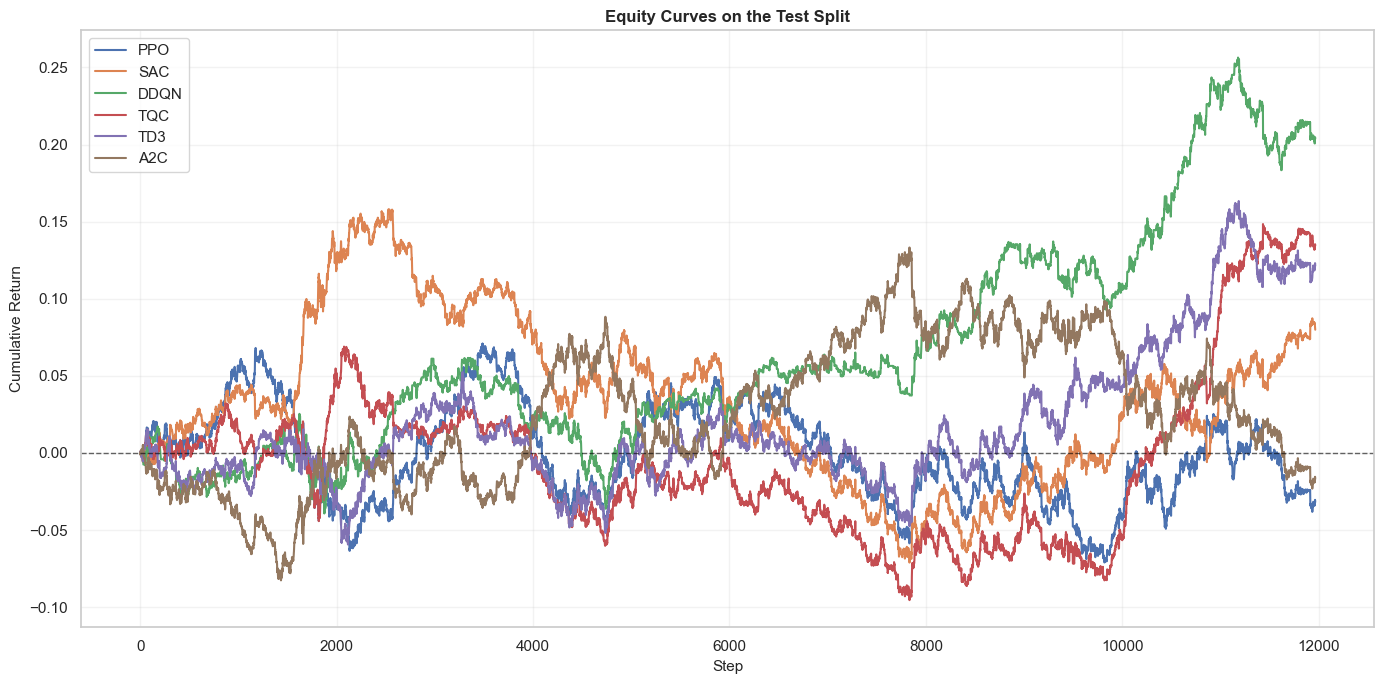

In [19]:
fig, axes = plt.subplots(2, 3, figsize=(18, 11))
heatmap_specs = [
    ("signed_action_corr", "Signed Action Correlation", "coolwarm", -1, 1),
    ("position_corr", "Position Correlation", "coolwarm", -1, 1),
    ("return_similarity", "Return Similarity", "viridis", 0, 1),
    ("trade_overlap", "Trade Overlap", "viridis", 0, 1),
    ("jsd_bits", "Jensen-Shannon Divergence (bits)", "magma", 0, None),
    ("euclidean", "Normalized Euclidean Distance", "magma", 0, None),
]

for ax, (key, title, cmap, vmin, vmax) in zip(axes.flatten(), heatmap_specs):
    data = pairwise[key]
    sns.heatmap(
        data,
        ax=ax,
        annot=True,
        fmt=".2f",
        cmap=cmap,
        vmin=vmin,
        vmax=vmax,
        square=True,
        cbar=True,
    )
    ax.set_title(title)

plt.tight_layout()
plt.show()


fig, axes = plt.subplots(2, 3, figsize=(18, 10))
axes = axes.flatten()
for idx, agent_name in enumerate(agent_order):
    ax = axes[idx]
    seq = trajectories[agent_name]["action_signals"]
    if agent_name in CONTINUOUS_AGENTS:
        ax.hist(seq, bins=20, density=True, alpha=0.8, color="#1f77b4", edgecolor="black")
        ax.set_title(f"{agent_name} | continuous")
    else:
        counts = [np.sum(seq == -1), np.sum(seq == 0), np.sum(seq == 1)]
        ax.bar([-1, 0, 1], np.asarray(counts) / max(len(seq), 1), color="#2ca02c", alpha=0.8)
        ax.set_xticks([-1, 0, 1])
        ax.set_title(f"{agent_name} | discrete")
    ax.set_xlabel("Action")
    ax.set_ylabel("Frequency")

plt.tight_layout()
plt.show()


sequence_matrix = np.vstack([
    standardized_sequence(trajectories[name]["action_signals"])
    for name in agent_order
])

pca = PCA(n_components=2, random_state=RANDOM_SEED)
pca_coords = pca.fit_transform(sequence_matrix)

tsne_perplexity = min(3, len(agent_order) - 1)
tsne = TSNE(
    n_components=2,
    perplexity=tsne_perplexity,
    init="pca",
    learning_rate="auto",
    random_state=RANDOM_SEED,
)
tsne_coords = tsne.fit_transform(sequence_matrix)

fig, axes = plt.subplots(1, 2, figsize=(16, 6))
for idx, agent_name in enumerate(agent_order):
    axes[0].scatter(pca_coords[idx, 0], pca_coords[idx, 1], s=90)
    axes[0].annotate(agent_name, (pca_coords[idx, 0], pca_coords[idx, 1]), xytext=(5, 5), textcoords="offset points")
    axes[1].scatter(tsne_coords[idx, 0], tsne_coords[idx, 1], s=90)
    axes[1].annotate(agent_name, (tsne_coords[idx, 0], tsne_coords[idx, 1]), xytext=(5, 5), textcoords="offset points")

axes[0].set_title("PCA of Action Trajectories")
axes[1].set_title(f"t-SNE of Action Trajectories (perplexity={tsne_perplexity})")
for ax in axes:
    ax.set_xlabel("Component 1")
    ax.set_ylabel("Component 2")
    ax.grid(True, alpha=0.25)

plt.tight_layout()
plt.show()


plt.figure(figsize=(14, 7))
for agent_name in agent_order:
    equity_curve = trajectories[agent_name]["equity"]
    cumulative_return = equity_curve / equity_curve[0] - 1.0
    plt.plot(cumulative_return, label=agent_name)

plt.axhline(0.0, color="black", linestyle="--", linewidth=1, alpha=0.6)
plt.title("Equity Curves on the Test Split")
plt.xlabel("Step")
plt.ylabel("Cumulative Return")
plt.legend()
plt.grid(True, alpha=0.25)
plt.tight_layout()
plt.show()

## 9. Diversity Summary and Saved Artifacts

The final step aggregates the pairwise matrices into compact summary scores and saves everything
needed to reproduce the analysis later.

In [20]:
triu = np.triu_indices(len(agent_order), k=1)

summary_rows = [
    {
        "metric": "avg_signed_action_corr",
        "value": float(np.mean(pairwise["signed_action_corr"].values[triu])),
    },
    {
        "metric": "avg_abs_action_similarity",
        "value": float(np.mean(pairwise["abs_action_similarity"].values[triu])),
    },
    {
        "metric": "avg_return_similarity",
        "value": float(np.mean(pairwise["return_similarity"].values[triu])),
    },
    {
        "metric": "avg_trade_overlap",
        "value": float(np.mean(pairwise["trade_overlap"].values[triu])),
    },
    {
        "metric": "avg_jsd_bits",
        "value": float(np.mean(pairwise["jsd_bits"].values[triu])),
    },
    {
        "metric": "avg_normalized_euclidean",
        "value": float(np.mean(pairwise["euclidean"].values[triu])),
    },
    {
        "metric": "avg_mean_abs_action_diff",
        "value": float(np.mean(pairwise["mean_abs_action_diff"].values[triu])),
    },
]

diversity_summary = pd.DataFrame(summary_rows).set_index("metric")
display(diversity_summary.style.format({"value": "{:.4f}"}))

per_agent_summary = pd.DataFrame(index=agent_order)
per_agent_summary["mean_signed_action_corr"] = [
    float(pairwise["signed_action_corr"].loc[name].drop(name).mean()) for name in agent_order
]
per_agent_summary["mean_abs_action_similarity"] = [
    float(pairwise["abs_action_similarity"].loc[name].drop(name).mean()) for name in agent_order
]
per_agent_summary["mean_return_similarity"] = [
    float(pairwise["return_similarity"].loc[name].drop(name).mean()) for name in agent_order
]
per_agent_summary["mean_trade_overlap"] = [
    float(pairwise["trade_overlap"].loc[name].drop(name).mean()) for name in agent_order
]
per_agent_summary["mean_jsd_bits"] = [
    float(pairwise["jsd_bits"].loc[name].drop(name).mean()) for name in agent_order
]
per_agent_summary["mean_euclidean"] = [
    float(pairwise["euclidean"].loc[name].drop(name).mean()) for name in agent_order
]
display(per_agent_summary.style.format("{:.4f}"))

results = {
    "asset": ASSET,
    "asset_type": ASSET_TYPE,
    "config_path": str(CONFIG_PATH),
    "test_data_path": str(TEST_DATA_PATH),
    "checkpoint_paths": {name: str(path) for name, path in checkpoint_paths.items()},
    "feature_columns": {
        name: trajectories[name]["feature_cols"] for name in agent_order
    },
    "trajectories": trajectories,
    "performance": performance_df,
    "pairwise": pairwise,
    "diversity_summary": diversity_summary,
    "per_agent_summary": per_agent_summary,
}

results_path = RESULTS_DIR / "diversity_results.pkl"
with results_path.open("wb") as fh:
    pickle.dump(results, fh)

performance_path = RESULTS_DIR / "diversity_performance.csv"
diversity_summary_path = RESULTS_DIR / "diversity_summary.csv"
per_agent_summary_path = RESULTS_DIR / "diversity_per_agent_summary.csv"

performance_df.to_csv(performance_path)
diversity_summary.to_csv(diversity_summary_path)
per_agent_summary.to_csv(per_agent_summary_path)

print(f"Saved results to: {results_path}")
print(f"Saved performance table to: {performance_path}")
print(f"Saved summary tables to: {diversity_summary_path} and {per_agent_summary_path}")

,value
metric,
avg_signed_action_corr,0.0922
avg_abs_action_similarity,0.2298
avg_return_similarity,0.2970
avg_trade_overlap,0.4547
avg_jsd_bits,0.1694
avg_normalized_euclidean,1.3366
avg_mean_abs_action_diff,0.9330


,mean_signed_action_corr,mean_abs_action_similarity,mean_return_similarity,mean_trade_overlap,mean_jsd_bits,mean_euclidean
PPO,0.1095,0.2756,0.2673,0.5128,0.1167,1.3201
SAC,0.1133,0.1789,0.3194,0.5023,0.1590,1.3267
DDQN,0.1465,0.1465,0.1306,0.3559,0.1960,1.3052
TQC,0.1671,0.2272,0.3634,0.5322,0.1259,1.2838
TD3,0.2104,0.3312,0.3292,0.5512,0.0916,1.2423
A2C,-0.1934,0.2192,0.3724,0.2735,0.3271,1.5413


Saved results to: c:\Users\Nabeel\Desktop\AET_itr1\storage\EURUSD\analysis\diversity_results.pkl
Saved performance table to: c:\Users\Nabeel\Desktop\AET_itr1\storage\EURUSD\analysis\diversity_performance.csv
Saved summary tables to: c:\Users\Nabeel\Desktop\AET_itr1\storage\EURUSD\analysis\diversity_summary.csv and c:\Users\Nabeel\Desktop\AET_itr1\storage\EURUSD\analysis\diversity_per_agent_summary.csv
